# Audio autoencoder

In [0]:
!pip -q install tensorflowjs

In [0]:
%matplotlib inline

# Utils
from glob import glob
import tqdm
from pathlib import Path
import datetime


# Numeros
import numpy as np
from scipy.interpolate import interp1d

# Redes neuronales
from keras.utils.vis_utils import model_to_dot, plot_model
from keras.models import Sequential, Model
from keras.layers import Input, Dense, Conv2D, MaxPooling2D, UpSampling2D, Flatten, Reshape, BatchNormalization
from keras.initializers import RandomNormal
from keras.optimizers import RMSprop, Adam
from keras import backend as K
from keras import regularizers
from keras.datasets import mnist
import keras as keras
import tensorflow as tf
import tensorflowjs as tfjs

# Visualización
import ipywidgets
import matplotlib.pyplot as plt
from IPython.display import Image, Audio, HTML
import PIL
import imageio

# Machine learning
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

# Audio
import librosa
import librosa.display

plt.rcParams['font.size']=20
plt.rcParams['figure.figsize']=(8,6)

DRAW = True

Using TensorFlow backend.


In [0]:
!pip install -U youtube-dl

     |████████████████████████████████| 1.8MB 3.5MB/s 


# Autoencoders <a name="ae"></a>

![](https://www.curiousily.com/media/data-imputation-2/mushroom_encoder.png)


Encoder

$Z = f(X)$

Z = Espacio Latente

Decoder

$X = f^{-1}(Z)$


## Bajamos un audio de youtube

In [0]:
!youtube-dl --extract-audio --audio-format wav --output audio.wav youtube.com/watch?v=GIHQivoISco

[youtube] GIHQivoISco: Downloading webpage
[youtube] GIHQivoISco: Downloading js player c31b936c
[youtube] GIHQivoISco: Downloading js player c31b936c
[download] Destination: audio.wav
[download] 100% of 7.59MiB in 00:00
[ffmpeg] Post-process file audio.wav exists, skipping


## Carjamos el audio y computamos el espectro

In [0]:
Sclip = -60
hop_length_ms = 10
duration = 60*2

sr = 22050
path = 'audio.wav'

hop_length = int(hop_length_ms/1000*sr)
win_length = hop_length*4

X = []
y = []
phases = []

for i,filename in enumerate(glob(path)):
    x,sr = librosa.load(filename, sr=sr, mono=True,duration=duration)
    x = np.trim_zeros(x)
    F = librosa.stft(x,n_fft=win_length, hop_length=hop_length).T
    phases.append(np.angle(F))
    S = 10*np.log10(np.abs(F)**2)
    S = S.clip(Sclip, None)-Sclip
    y.append(np.ones(S.shape[0])*i)
    X.append(S)
    
phases = np.vstack(phases)    
X = np.vstack(X)
Xmax = X.max()
X = X/Xmax
y = np.hstack(y)

In [0]:
print('Win length:',win_length,', Hop length:', hop_length)
print('Data shape:',X.shape)
print('Length min:',X.shape[0]*hop_length_ms/1000/60)
n_features = X.shape[1]

Win length: 880 , Hop length: 220
Data shape: (11465, 441)
Length min: 1.9108333333333334


## Visuzalición del data set

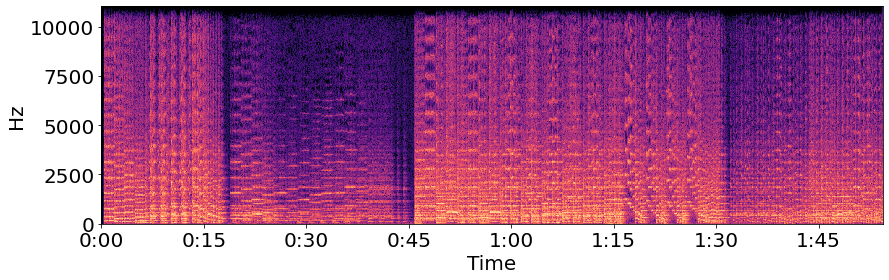

In [0]:
if DRAW:
    plt.figure(figsize=(14,4))
    librosa.display.specshow(X.T,y_axis='linear',x_axis='time',hop_length=hop_length);

## Escuchamos como se reconstruye el audio previo a hacer el autoencoder. Para eso hay que inventar una fase, en este caso es random.


'Fase original'

'Fase random'

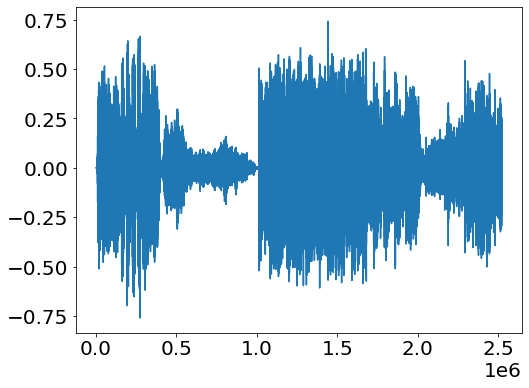

In [0]:
if DRAW:
    X_ = np.sqrt(10**((X*Xmax+Sclip)/10))*np.exp(1j*phases)
    x_ = librosa.istft(X_.T,hop_length=hop_length, win_length=win_length)

    plt.plot(x_)
    display('Fase original')
    display(Audio(x_,rate=sr))

    phases_ = np.random.rand(*X.shape)*2*np.pi
    X_ = np.sqrt(10**((X*Xmax+Sclip)/10))*np.exp(1j*phases_)
    x_ = librosa.istft(X_.T,hop_length=hop_length, win_length=win_length)

    display('Fase random')
    display(Audio(x_,rate=sr))

## Separamos en train y val

In [0]:
X_train, X_val, y_train, y_val = train_test_split(X, y,  test_size=0.05, shuffle=True)
print('Length mins:', X_train.shape[0]*hop_length_ms/1000/60)

Length mins: 1.8151666666666666


### Armamos un autoencoder denso de 8 capas

In [0]:
K.clear_session()

input_mag = Input(shape=(n_features,))

kr_init = keras.initializers.glorot_normal()

layers = [512,256,128,64,32,16,8]
latent_dim = layers[-1]

x = input_mag
for l in layers:
    x = BatchNormalization()(x)
    x = Dense(l, activation='relu', kernel_initializer=kr_init)(x)
encoded = x

encoder = Model(input_mag, encoded)
latent_inputs = Input(shape=(latent_dim,), name='z')
x = latent_inputs
for l in layers[::-1][1:]:
    x = BatchNormalization()(x)
    x = Dense(l, activation='relu', kernel_initializer=kr_init)(x)
decoded = Dense(n_features, activation='relu', kernel_initializer=kr_init)(x)

decoder = Model(latent_inputs, decoded, name='decoder')

outputs = decoder(encoder(input_mag))
autoencoder = Model(input_mag, outputs, name='autoencoder')

opt = RMSprop(0.005)
opt = Adam(0.002, clipnorm=0.5)

autoencoder.compile(optimizer=opt, loss='mse', metrics=['mse'])
print(autoencoder.summary())

logdir = Path("logs", datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
tensorboard_callback = keras.callbacks.TensorBoard(logdir, histogram_freq=1)


Model: "autoencoder"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         (None, 441)               0         
_________________________________________________________________
model_1 (Model)              (None, 8)                 407324    
_________________________________________________________________
decoder (Model)              (None, 441)               403977    
Total params: 811,301
Trainable params: 807,395
Non-trainable params: 3,906
_________________________________________________________________
None


In [0]:
silence = np.zeros([int(X_train.shape[0]*0.1),X_train.shape[1]])

Train on 11980 samples, validate on 574 samples
Epoch 1/120
11980/11980 [==============================] - 5s 384us/step - loss: 0.0251 - mse: 0.0251 - val_loss: 0.0427 - val_mse: 0.0427
Epoch 2/120
11980/11980 [==============================] - 3s 217us/step - loss: 0.0088 - mse: 0.0088 - val_loss: 0.0131 - val_mse: 0.0131
Epoch 3/120
11980/11980 [==============================] - 3s 223us/step - loss: 0.0084 - mse: 0.0084 - val_loss: 0.0095 - val_mse: 0.0095
Epoch 4/120
11980/11980 [==============================] - 3s 218us/step - loss: 0.0080 - mse: 0.0080 - val_loss: 0.0082 - val_mse: 0.0082
Epoch 5/120
11980/11980 [==============================] - 3s 216us/step - loss: 0.0079 - mse: 0.0079 - val_loss: 0.0124 - val_mse: 0.0124
Epoch 6/120
11980/11980 [==============================] - 3s 219us/step - loss: 0.0080 - mse: 0.0080 - val_loss: 0.0083 - val_mse: 0.0083
Epoch 7/120
11980/11980 [==============================] - 3s 218us/step - loss: 0.0072 - mse: 0.0072 - val_loss: 0.00

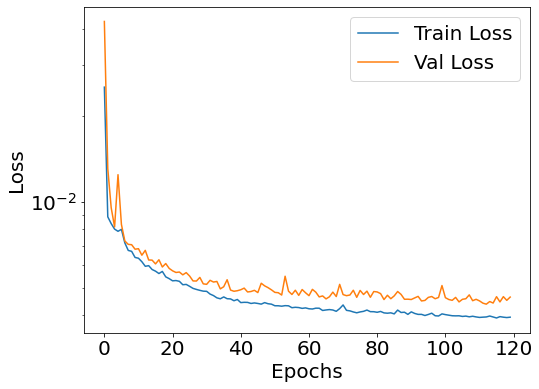

In [0]:
h = autoencoder.fit(np.vstack([silence, X_train]), np.vstack([silence, X_train]),
                epochs=120,
                batch_size=128,
                shuffle=True, 
                validation_data= (X_val,X_val),
                callbacks=[tensorboard_callback])

plt.semilogy(h.history['loss'], label='Train Loss')
plt.semilogy(h.history['val_loss'], label = 'Val Loss');
plt.xlabel('Epochs')
plt.ylabel('Loss');
plt.legend();

In [0]:
%load_ext tensorboard
%tensorboard --logdir logs

<IPython.core.display.Javascript object>

## Podemos escuchar la reconstrucción

'Fase original'

'Fase random'

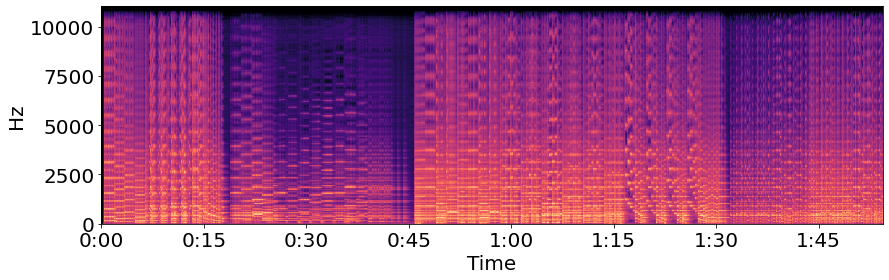

In [0]:
Y = autoencoder.predict(X)
Y = Y-np.min(Y)

if DRAW:
    plt.figure(figsize=(14,4))
    librosa.display.specshow(Y.T,y_axis='linear',x_axis='time',hop_length=hop_length);

phase = phases
Y_ = np.sqrt(10**((Y*Xmax+Sclip)/10))*np.exp(1j*phase)
y_ = librosa.istft(Y_.T,hop_length=hop_length, win_length=win_length)

display('Fase original')
display(Audio(y_,rate=sr))

phase = np.random.rand(*Y.shape)*2*np.pi
Y_ = np.sqrt(10**((Y*Xmax+Sclip)/10))*np.exp(1j*phase)
y_ = librosa.istft(Y_.T,hop_length=hop_length, win_length=win_length)

display('Fase random')
display(Audio(y_,rate=sr))

#### Veamos la actividad en la capa del medio

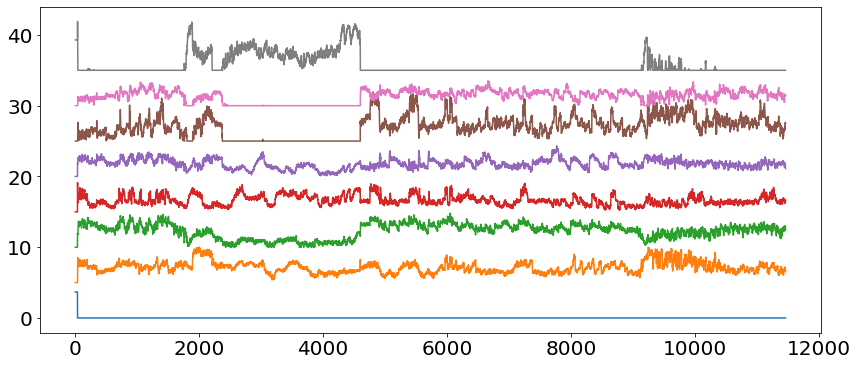

In [0]:
Z = encoder.predict(X)
plt.figure(figsize=(14,6))
plt.plot(Z+np.arange(Z.shape[1])*5);

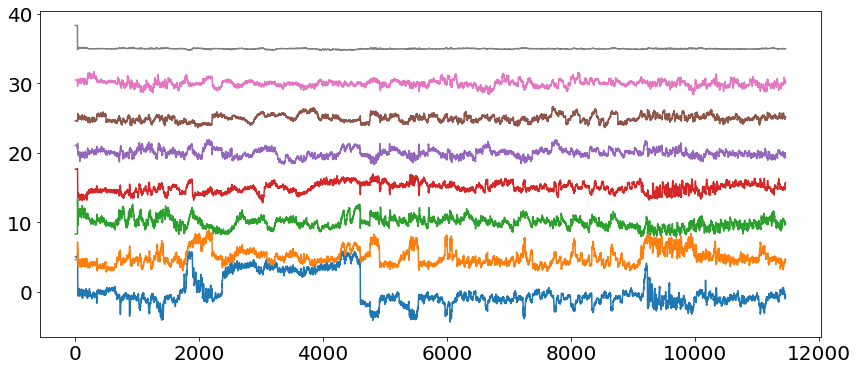

In [0]:
pca = PCA()
Zpca = pca.fit_transform(Z)
plt.figure(figsize=(14,6))
plt.plot(Zpca+np.arange(Z.shape[1])*5);

In [0]:
sr_hop = sr/hop_length
dur = 30
N = int(dur*sr_hop)

for pc_n in range(len(layers)):

  z = np.zeros((N,layers[-1]))

  z[:,pc_n] = np.linspace(Zpca[:,pc_n].min()*1.01,Zpca[:,pc_n].max()*1.01,N)

  Z = pca.inverse_transform(z)
  Y = decoder.predict(Z)

  Y = Y-np.min(Y)
  # plt.figure(figsize=(14,4))
  # librosa.display.specshow(Y.T,y_axis='linear',x_axis='time',hop_length=hop_length);

  phase = np.random.rand(*Y.shape)*2*np.pi
  Y_ = np.sqrt(10**((Y*Xmax+Sclip)/10))*np.exp(1j*phase)
  y_ = librosa.istft(Y_.T,hop_length=hop_length, win_length=win_length)

  # plt.figure(figsize=(14,4))
  # plt.plot(y_)
  print('Principal component {}'.format(pc_n))
  display(Audio(y_,rate=sr))

Principal component 0


Principal component 1


Principal component 2


Principal component 3


Principal component 4


Principal component 5


Principal component 6


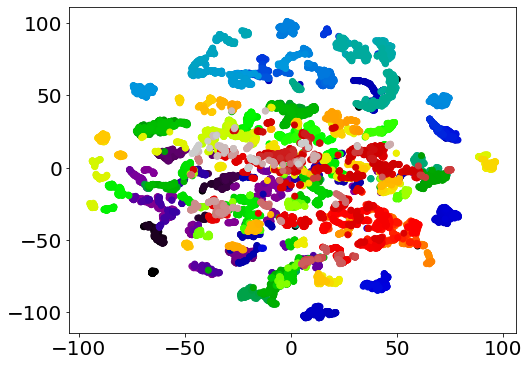

In [0]:
time = np.arange(X.shape[0])
Z = encoder.predict(X)
tsne = TSNE(n_components=2)
data2d = tsne.fit_transform(Z)
plt.scatter(data2d[:,0],data2d[:,1],c=time,cmap=plt.cm.nipy_spectral)

## Sinteticemos audio generando trayectorias en el espacio latente

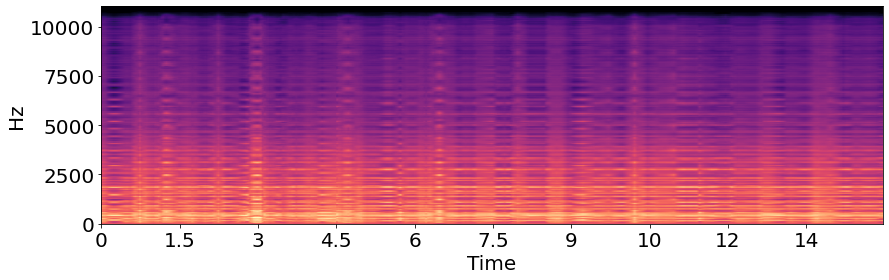

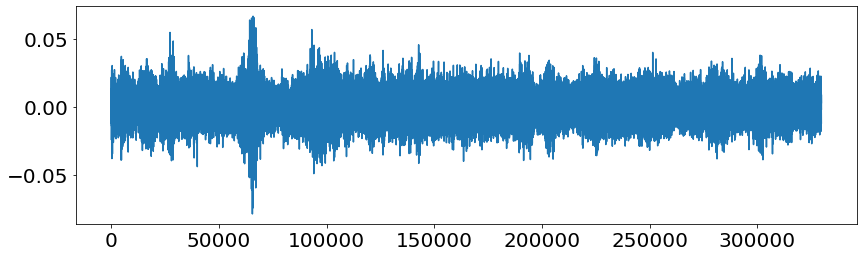

In [0]:
T = 0.25
T_frames = int(T*sr/hop_length)

N = 60
Z = []
z_prev = np.random.rand(layers[-1])
for i in range(N):
    z_rand = np.random.rand(layers[-1])
    linfit = interp1d([0,1], [z_prev, z_rand], axis=0, kind='linear')
    z_interp = linfit(np.linspace(0,1,T_frames))
    z_prev = z_rand
    Z.append(z_interp)
Z = np.vstack(Z)
Y = decoder.predict(Z)

Y = Y-np.min(Y)
plt.figure(figsize=(14,4))
librosa.display.specshow(Y.T,y_axis='linear',x_axis='time',hop_length=hop_length);

phase = np.random.rand(*Y.shape)*2*np.pi
# phase = np.zeros(Y.shape)
Y_ = np.sqrt(10**((Y*Xmax+Sclip)/10))*np.exp(1j*phase)
y_ = librosa.istft(Y_.T,hop_length=hop_length, win_length=win_length)
plt.figure(figsize=(14,4))

plt.plot(y_)
Audio(y_,rate=sr)

In [0]:
tfjs.converters.save_keras_model(autoencoder, 'tfjs')
!zip autoencoder.zip tfjs/*

In [ ]:
import os

checkpoint_directory = "/tmp/training_checkpoints"
checkpoint_prefix = os.path.join(checkpoint_directory, "ckpt")

print(autoencoder.output.op.name)
saver = tf.train.Checkpoint()
saver.save(file_prefix=checkpoint_prefix)
